# Campaign analysis: the 9 November runs

The 45 runs queued with `tools/run_campaign.py`
(`E:\MasterProject\checkpoints\campaign_20261109_161426_f78322dc`, all done by 12 Nov), read together
with the earlier batches. Part 1 sets the high and low states; each later part gives a question, its
test, figures and a conclusion.

- Living species are counted in the largest cluster of open sites.
- Grey band: from the exit line up to the entry line of the high state. Where the runs in a panel
  have different lines, each run's lines are drawn in its colour (dashed: entry, dotted: exit).
- Means and "% high" cover the second half of each run's window.
- One or two runs per setting, and chance moves runs a lot (D8), so only large, consistent
  differences count.

Papers in `articles/`: Mitarai et al. 2012 (the model, Fig. 6), Uekermann et al. 2017 (states,
§III B), Hofer & Sneppen 2024 (diversity grows as √area).

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

if Path.cwd().name == "analysis":
    os.chdir("..")
sys.path[:0] = [os.getcwd(), os.path.join(os.getcwd(), "analysis")]
import campaign_runs as C

M = 1_000_000
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", C.PARENT_COLOR  # Validated palette.
GAMMA_SWAP = "no_short_cycles_gamma_p30_from_g003_20261022_005553_5940261e"
ALL_CYCLES_P05 = "gamma_sweep_perc05_largest_20261006_113609_5a0ff663"

runs, _, _ = C.catalogue()  # Every finished run: the campaign and the earlier batches.
info = C.state_lines(runs)  # Modes and lines per pool of alike runs.
runs = C.classify(runs, info)
swap = {run["gamma"]: run for run in C.select(runs, batch=GAMMA_SWAP)}

## 1. High and low states from the modes of alike runs

**Question.** Where do the high and low states lie? The old lines (high from 50 species until 10)
were set by eye.

**Test.** The rule of Uekermann, Mathiesen & Mitarai (2017, §III B), applied to living species (the
paper used the frozen boundary length, which our runs do not record):
- Runs with the same γ, p and cycle rule form a pool, over α, seed and parent.
- A pool's modes are the peaks of its distribution that hold ≥ 5% of the samples, with a dip of
  ≥ 10% between them.
- With M1 the high mode, a run enters the high state above 0.5·M1 and leaves it below 0.1·M1, on its
  count smoothed over 0.2M steps. A pool uses its own lines only if its low mode lies below 0.1·M1.
- Other pools borrow the lines of the nearest such pool with the same rule (same p, else same γ).
  Without one, they are *low only* or *unresolved*.

Rows are drawn per unit of log species, so areas are shares of the samples. Dots mark the modes, which
are found on the plain count. Ticks mark the entry (solid) and exit (dotted) lines, whose values are on
the right; the number of runs is in brackets.

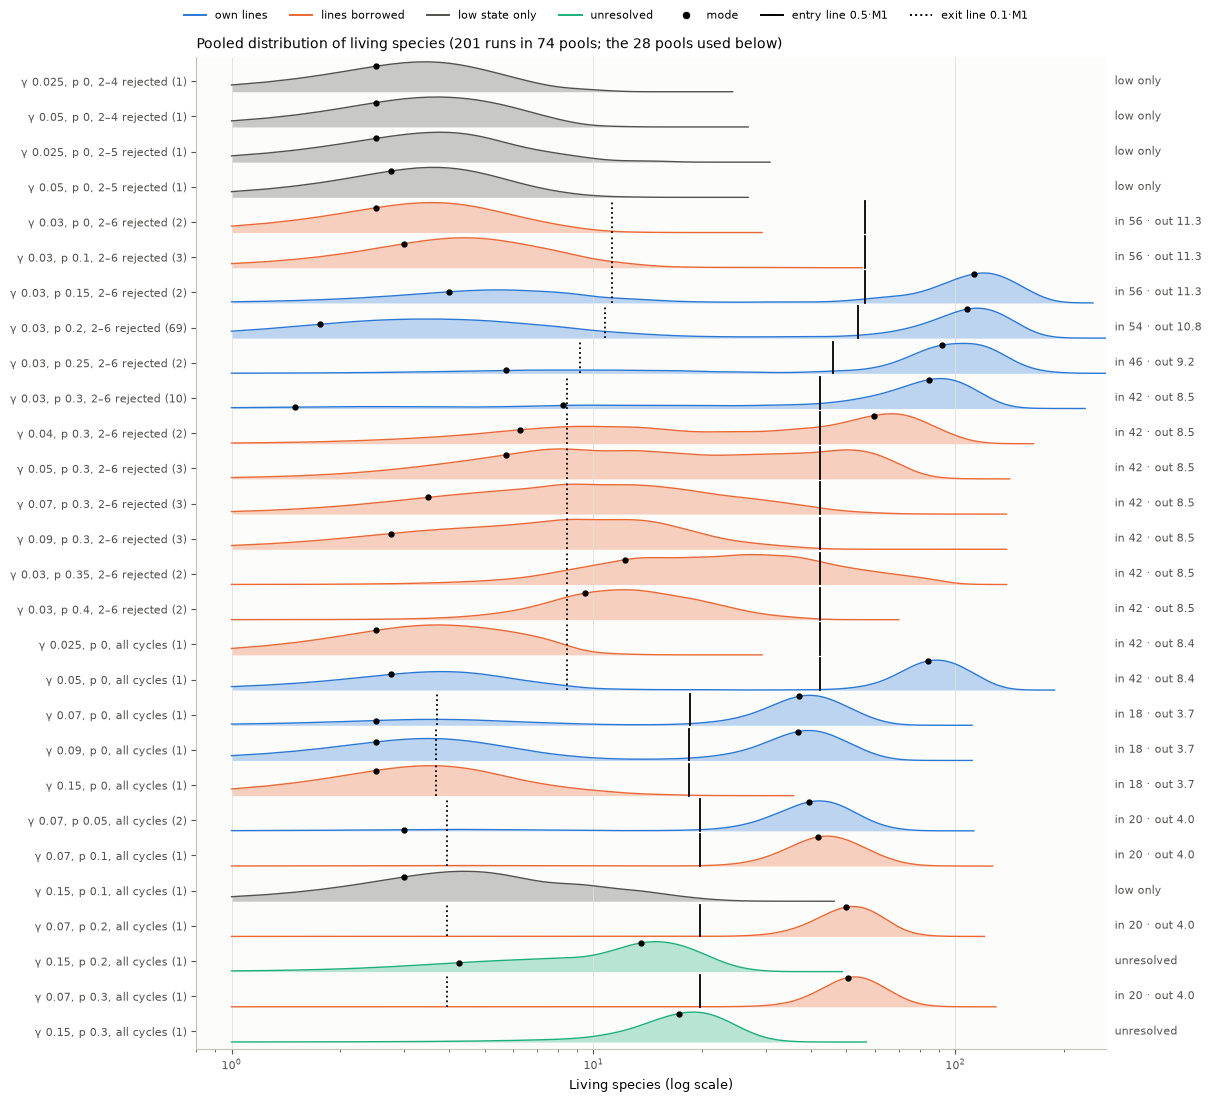

In [2]:
shown = {run["pool"] for run in runs if run["group"]}
shown |= {swap[g]["pool"] for g in (0.04, 0.05, 0.07, 0.09)}
shown |= {(0.07, 0.0, None), (0.07, 0.05, None)}  # The D1 run and the p = 0.05 all-cycles sweep.
shown |= {info[key]["source"] for key in list(shown) if info[key]["kind"] == "borrowed"}
order = sorted(shown, key=lambda key: (key[2] is None, key[2] or 0, key[1], key[0]))
KINDS = {"own": (BLUE, "own lines"), "borrowed": (ORANGE, "lines borrowed"),
         "low only": (GREY, "low state only"), "unresolved": (AQUA, "unresolved")}

with plt.rc_context(C.RESULT_STYLE):
    fig, ax = plt.subplots(figsize=(12, 0.34 * len(order) + 1.4), layout="constrained")
    for row, key in enumerate(order):
        item, y = info[key], len(order) - 1 - row
        color = KINDS[item["kind"]][0]
        keep = item["grid"] >= 0.8
        grid = item["grid"][keep]
        per_log = grid * item["density"][keep]  # Per unit of log species: areas show shares.
        height = 0.85 * per_log / per_log.max()
        ax.fill_between(grid, y, y + height, color=color, alpha=0.3, lw=0)
        ax.plot(grid, y + height, color=color, lw=1)
        for mode in item["modes"]:
            ax.plot(mode["location"], y + np.interp(mode["location"], grid, height), "o",
                    color="black", ms=3.5, zorder=4)
        if "enter" in item:
            ax.plot([item["enter"]] * 2, [y, y + 0.9], color="black", lw=1.3)
            ax.plot([item["exit"]] * 2, [y, y + 0.9], color="black", lw=1.3, ls=":")
            text = f"in {item['enter']:.0f} · out {item['exit']:.1f}"
        else:
            text = item["kind"]
        ax.text(1.01, y + 0.3, text, transform=ax.get_yaxis_transform(), fontsize=8, va="center",
                color=C.PARENT_COLOR)
    ax.set_xscale("log")
    ax.set_xlim(0.8, 260)
    ax.set_ylim(-0.2, len(order))
    ax.set_yticks([len(order) - 1 - row + 0.3 for row in range(len(order))],
                  [f"{C.pool_name(key)} ({info[key]['runs']})" for key in order], fontsize=8)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Living species (log scale)")
    ax.set_title(f"Pooled distribution of living species ({len(runs)} runs in {len(info)} pools; "
                 f"the {len(order)} pools used below)")
    handles = [C.handle(color, None, label) for color, label in KINDS.values()]
    handles += [C.handle("black", "o", "mode", ls="none"), C.handle("black", None, "entry line 0.5·M1"),
                C.handle("black", None, "exit line 0.1·M1", ls=":")]
    fig.legend(handles=handles, loc="outside upper center", ncols=7)
    plt.show()

**Conclusion.** The low mode lies at 1.5–6 species everywhere, but the high mode depends on the setting.
- **Lengths 2–6 rejected, γ = 0.03:** the high mode falls from 113 to 85 species as p goes from 0.15 to
  0.3. The lines (in 42–56, out 8–11) are close to the old ones.
- **All cycles:** 84 species at γ = 0.05, but 37–40 at γ = 0.07–0.09 (p ≤ 0.05), with entry lines of
  18–20. The D1 run's plateau near 40 species is therefore a high state: high for 86% of 25–50M, not
  the 16% the old lines gave.
- **Unresolved:** all cycles at γ = 0.15 with p = 0.2 and 0.3 (one run each, 11–17 species).
- *Caveat:* living species fluctuate more than the frozen boundary length the paper used.

## 2. Q5: does γ act through link density or through the arrival rate?

**Question.** Raising γ raises both the link density and the arrival rate α·γ. Which of the two lost
the high state when parent B was swapped to γ ≥ 0.055 (D9)?

**Test.** Branches of parent B at 50M (p = 0.3, γ = 0.03, α = 0.0125, lengths 2–6 rejected), 100M each:

| Arm | γ | Arrival rate α·γ |
|---|---|---|
| γ swap (earlier batch) | γ′ | 0.0125·γ′ |
| Fixed rate | γ′ | 3.75×10⁻⁴ (α lowered) |
| Raised α | 0.03 | 0.0125·γ′ (α raised) |

The control (dashed grey) is the γ swap's unchanged branch. All runs use parent B's lines.

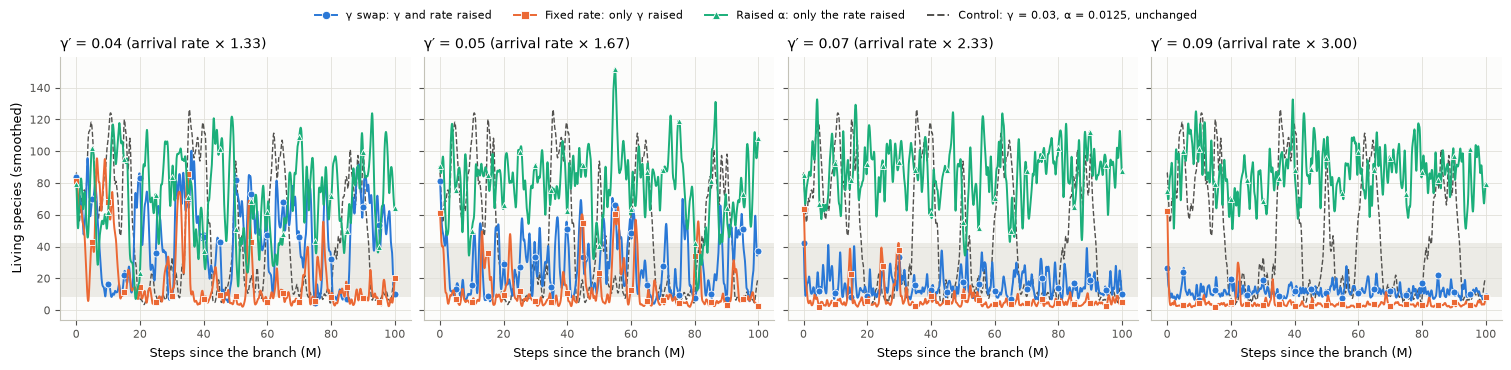

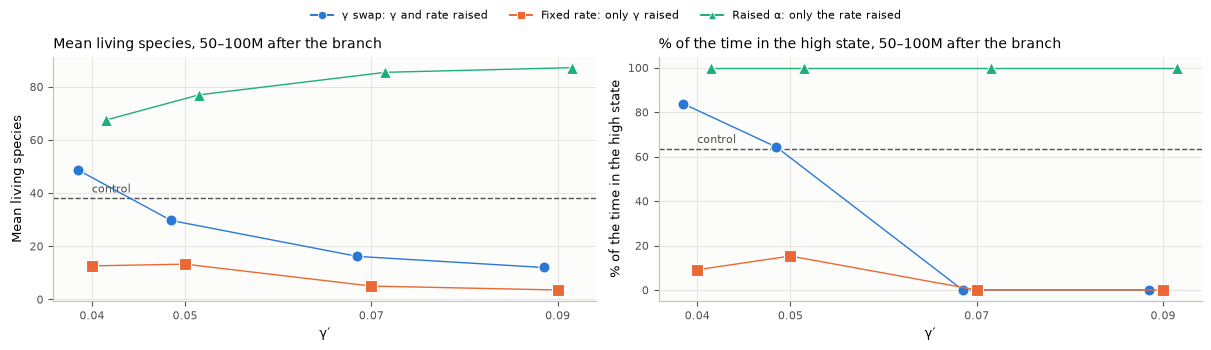

In [3]:
q5 = [run for run in runs if run["group"] in ("q5_fixed_rate_from_B", "q5_raised_alpha_from_B")]
control = swap[0.03]
TARGETS = (0.04, 0.05, 0.07, 0.09)
ARMS = [  # (label, colour, marker, run per target γ′)
    ("γ swap: γ and rate raised", BLUE, "o", {g: swap[g] for g in TARGETS}),
    ("Fixed rate: only γ raised", ORANGE, "s",
     {run["gamma"]: run for run in q5 if run["group"] == "q5_fixed_rate_from_B"}),
    ("Raised α: only the rate raised", AQUA, "^",
     {round(run["alpha"] * 0.03 / 0.0125, 3): run for run in q5 if run["group"] == "q5_raised_alpha_from_B"}),
]
CONTROL_LABEL = "Control: γ = 0.03, α = 0.0125, unchanged"

with plt.rc_context(C.RESULT_STYLE):
    fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True, layout="constrained")
    for ax, g in zip(axes, TARGETS):
        C.state_band(ax, [(arm[g], color) for _, color, _, arm in ARMS] + [(control, GREY)])
        ax.plot(control["elapsed"], control["smoothed"], color=GREY, lw=1, ls="--", zorder=2)
        for label, color, marker, arm in ARMS:
            C.draw_trace(ax, arm[g], color, marker, label, raw=False)
        ax.set(title=f"γ′ = {g:g} (arrival rate × {g / 0.03:.2f})", xlabel="Steps since the branch (M)")
    axes[0].set_ylabel("Living species (smoothed)")
    fig.legend(handles=[C.handle(c, m, l) for l, c, m, _ in ARMS]
               + [C.handle(GREY, None, CONTROL_LABEL, ls="--")], loc="outside upper center", ncols=4)
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), layout="constrained")
    for ax, field, scale, ylabel in ((axes[0], "mean", 1, "Mean living species"),
                                     (axes[1], "share_high", 100, "% of the time in the high state")):
        ax.axhline(scale * control[field], color=GREY, ls="--", lw=1)
        ax.annotate("control", (TARGETS[0], scale * control[field]), xytext=(0, 4),
                    textcoords="offset points", fontsize=8, color=GREY)
        for offset, (label, color, marker, arm) in zip((-0.0015, 0, 0.0015), ARMS):
            ax.plot([g + offset for g in TARGETS], [scale * arm[g][field] for g in TARGETS], color=color,
                    marker=marker, ms=8, lw=1, mec="white", mew=0.8, label=label)
        ax.set(xlabel="γ′", xticks=TARGETS, ylabel=ylabel, title=f"{ylabel}, 50–100M after the branch")
    fig.legend(handles=[C.handle(c, m, l) for l, c, m, _ in ARMS], loc="outside upper center", ncols=3)
    plt.show()

**Conclusion.** γ acts through link density; the arrival rate sets how long the community stays high.
- **Only the rate raised:** high through all of 50–100M at every γ′ (mean 68–87 species). The control
  had 38 species and was high 64% of the time.
- **Only γ raised:** never high in the second half at γ′ ≥ 0.07, and high only 9–15% of the time at
  0.04–0.05, against 64–84% in the swap with its higher rate.
- This matches Uekermann et al. (2017): γ sets which states exist, α the time spent in each.
- *Caveat:* one run per cell. The fixed-rate arm lowers α to 0.004–0.009, where parent A collapsed on
  its own (D7).

## 3. Q7: is the gap to the paper's Fig. 6 only the rejection threshold?

**Question.** In the paper's quasistatic runs (Mitarai et al. 2012, Fig. 6(A)), rejecting cycles of
length 2–4 raised diversity, and rejecting 2–5 left γ = 0.05 with a single species. Our runs reject 2–6
and lose diversity at p = 0. Is that only because we reject more lengths?

**Test.** Fresh runs from one species at p = 0, α = 0.0125, 50M steps: γ = 0.025 and 0.05, each with all
cycles allowed, 2–4 rejected and 2–5 rejected (one run each). The reference is the p ladder's two p = 0
runs (γ = 0.03, 2–6 rejected) over 0–50M.

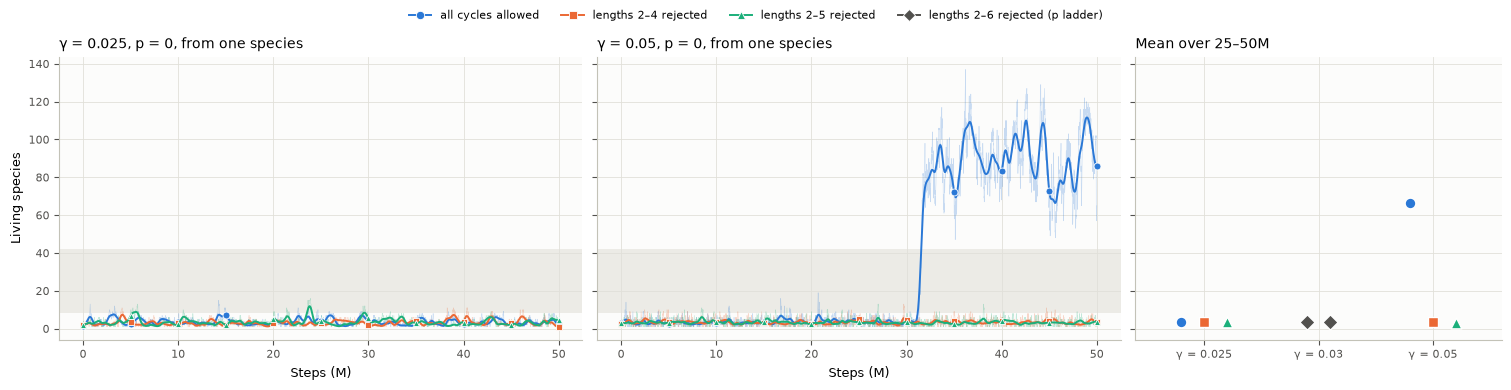

In [4]:
q7 = C.select(runs, group="q7_threshold_p0")
p0 = C.classify([run for run in C.select(runs, group="q3_p_ladder_g003") if run["p"] == 0],
                info, start=0, length=50 * M)
RULES = {None: ("all cycles allowed", BLUE, "o"), 4: ("lengths 2–4 rejected", ORANGE, "s"),
         5: ("lengths 2–5 rejected", AQUA, "^"), 6: ("lengths 2–6 rejected (p ladder)", GREY, "D")}

with plt.rc_context(C.RESULT_STYLE):
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True, layout="constrained",
                             gridspec_kw={"width_ratios": [1, 1, 0.7]})
    for ax, g in zip(axes, (0.025, 0.05)):
        panel = [run for run in q7 if run["gamma"] == g]
        C.state_band(ax, [(run, RULES[run["rule"]][1]) for run in panel])
        for run in panel:
            C.draw_trace(ax, run, *RULES[run["rule"]][1:], RULES[run["rule"]][0])
        ax.set(title=f"γ = {g:g}, p = 0, from one species", xlabel="Steps (M)")
    axes[0].set_ylabel("Living species")
    ax = axes[2]
    slot = {0.025: 0, 0.03: 1, 0.05: 2}
    offset = {None: -0.2, 4: 0.0, 5: 0.2}
    for index, run in enumerate(q7 + p0):
        label, color, marker = RULES[run["rule"]]
        x = slot[run["gamma"]] + offset.get(run["rule"], -0.1 + 0.2 * (index % 2))
        ax.scatter(x, run["mean"], color=color, marker=marker, s=60, edgecolors="white", zorder=3)
    ax.set(xticks=range(3), xticklabels=["γ = 0.025", "γ = 0.03", "γ = 0.05"], xlim=(-0.6, 2.6),
           title="Mean over 25–50M")
    fig.legend(handles=[C.handle(c, m, l) for l, c, m in RULES.values()],
               loc="outside upper center", ncols=4)
    plt.show()

**Conclusion.** No: in our dynamics even rejecting lengths 2–4 stops diversity forming.
- **Only γ = 0.05 with all cycles allowed became diverse.** It rose at 31.6M and was high for 74% of
  25–50M (mean 67 species).
- **Every other run stayed near 3 species,** every rejection rule included.
- *Caveats:* the paper started from a diverse state with Γ cleared, ours from one species. At
  γ = 0.025, 50M may be too short for a rise. The quasistatic half of Q7 needs new code.

## 4. D3 redo: do blocked sites raise diversity when all cycles are allowed?

**Question.** D3 (γ = 0.15: 7 → 52 species as p went from 0.075 to 0.2) was withdrawn because most of
those species sat in cut-off pockets. Does an effect remain in the largest cluster?

**Test.** Fresh runs from one species, all cycles allowed, α = 0.0125, 50M steps, one run per cell:
γ = 0.15 at p = 0–0.3 and γ = 0.07 at p = 0.1–0.3. At γ = 0.07, p = 0 is the D1 run's first 50M, and the
hollow circles are the two p = 0.05 sweep branches (run from 20M to 70M).

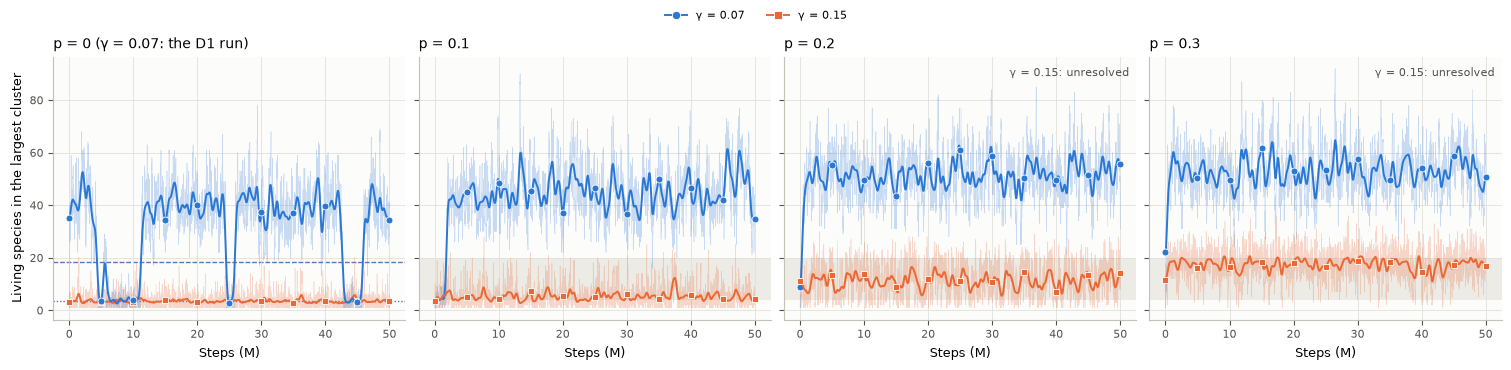

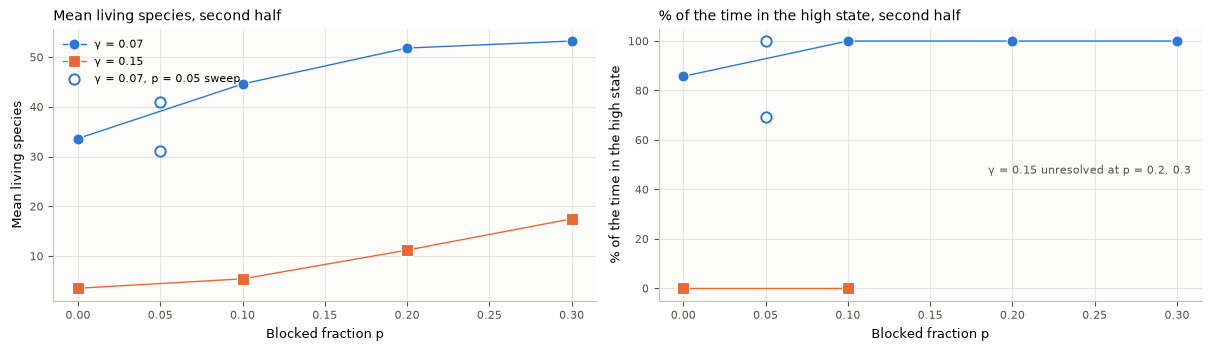

In [5]:
d3 = C.select(runs, group="d3_all_cycles_redo")
d1 = C.classify(C.select(runs, batch="gamma_07_alpha_0125"), info, start=0, length=50 * M)
p05 = [run for run in C.select(runs, batch=ALL_CYCLES_P05) if run["gamma"] == 0.07]
STYLE = {0.07: (BLUE, "o"), 0.15: (ORANGE, "s")}
d3_runs = d3 + d1

with plt.rc_context(C.RESULT_STYLE):
    fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True, layout="constrained")
    for ax, p in zip(axes, (0, 0.1, 0.2, 0.3)):
        panel = [run for run in d3_runs if run["p"] == p]
        C.state_band(ax, [(run, STYLE[run["gamma"]][0]) for run in panel])
        for run in panel:
            C.draw_trace(ax, run, *STYLE[run["gamma"]], f"γ = {run['gamma']:g}")
        C.note(ax, [f"γ = {run['gamma']:g}: unresolved" for run in panel if run["high"] is None])
        ax.set(title=f"p = {p:g}" + (" (γ = 0.07: the D1 run)" if p == 0 else ""), xlabel="Steps (M)")
    axes[0].set_ylabel("Living species in the largest cluster")
    fig.legend(handles=[C.handle(c, m, f"γ = {g:g}") for g, (c, m) in STYLE.items()],
               loc="outside upper center", ncols=2)
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), layout="constrained")
    for ax, field, scale, ylabel in ((axes[0], "mean", 1, "Mean living species"),
                                     (axes[1], "share_high", 100, "% of the time in the high state")):
        for g, (color, marker) in STYLE.items():
            line = sorted((run for run in d3_runs if run["gamma"] == g and np.isfinite(run[field])),
                          key=lambda run: run["p"])
            ax.plot([run["p"] for run in line], [scale * run[field] for run in line], color=color,
                    marker=marker, ms=8, lw=1, mec="white", mew=0.8, label=f"γ = {g:g}")
        ax.scatter([0.05] * len(p05), [scale * run[field] for run in p05], s=55, facecolors="white",
                   edgecolors=BLUE, linewidths=1.4, zorder=3, label="γ = 0.07, p = 0.05 sweep")
        ax.set(xlabel="Blocked fraction p", ylabel=ylabel, title=f"{ylabel}, second half")
    C.note(axes[1], ["γ = 0.15 unresolved at p = 0.2, 0.3"], y=0.5)
    axes[0].legend(loc="upper left")
    plt.show()

**Conclusion.** Blocked sites keep γ = 0.07 high. At γ = 0.15 they add species, but not clearly a high
state.
- **γ = 0.07:** at p = 0.1–0.3 the runs rose within 2M and stayed high (mean 45–53 species). The p = 0
  run was high for 86% of 25–50M but collapsed three times. The p = 0.05 branches were high for 100% and
  69% of their second half.
- **γ = 0.15:** low at p = 0 and 0.1 (mean 3.5 and 5.4 species). At p = 0.2–0.3 the largest cluster held
  11–17 species, which part 1 leaves unresolved. The withdrawn claim was 52 species at p = 0.2.
- *Caveat:* one run per cell. More seeds at γ = 0.15, p = 0.2–0.3 would show whether a high mode exists
  there.

## 5. Q4: is the hysteresis in α bistability, or too little time?

**Question.** At α ≤ 0.002 an established community persisted for 100M, yet fresh runs at that α never
became diverse (D7). Does it persist for good?

**Test.** Branches made at 50M, with each parent's runs on its own pool's lines:
- **Extensions:** parent A's α-sweep branches r1 and r2 (siblings) at α = 0.001 and 0.002, continued
  from 150M to 350M (dotted line).
- **Second parent:** parent B's branches at α = 0.001 and 0.002, to 150M.
- **Controls at α = 0.0125:** two branches of parent A (s1, s2), and the γ swap's unchanged branch for
  parent B.

The right panel counts how long each community stayed high in arrivals, α·γ·t, since a step at low α
brings fewer newcomers.

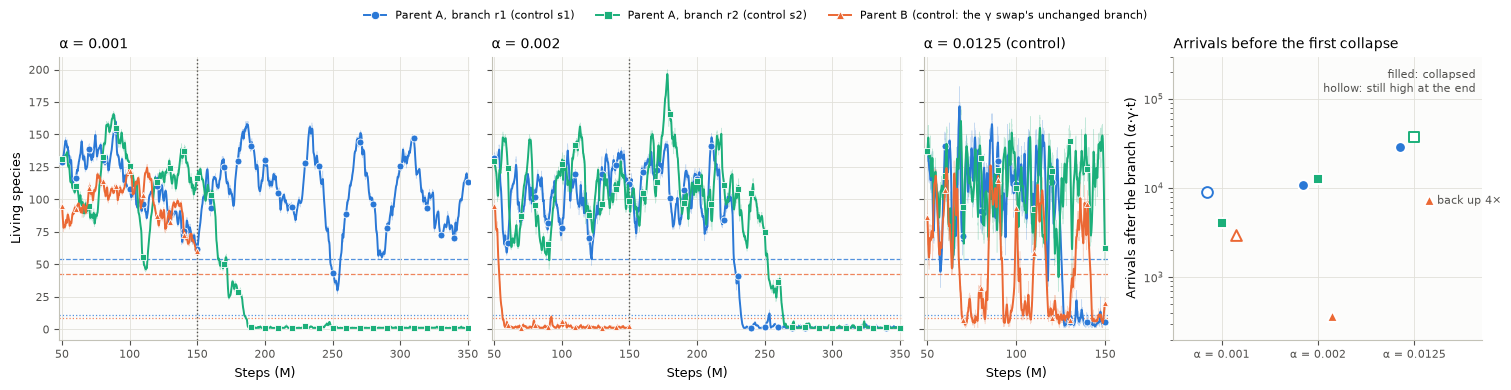

In [6]:
COLUMNS = (0.001, 0.002, 0.0125)
ROLES = [  # (legend label, colour, marker, run id per α; None is parent B's γ-swap control)
    ("Parent A, branch r1 (control s1)", BLUE, "o",
     {0.001: "q4_extend_low_alpha/r1_a0.001", 0.002: "q4_extend_low_alpha/r1_a0.002",
      0.0125: "q4_alpha_control_from_A/g0.03_a0.0125_s1"}),
    ("Parent A, branch r2 (control s2)", AQUA, "s",
     {0.001: "q4_extend_low_alpha/r2_a0.001", 0.002: "q4_extend_low_alpha/r2_a0.002",
      0.0125: "q4_alpha_control_from_A/g0.03_a0.0125_s2"}),
    ("Parent B (control: the γ swap's unchanged branch)", ORANGE, "^",
     {0.001: "q4_low_alpha_from_B/g0.03_a0.001", 0.002: "q4_low_alpha_from_B/g0.03_a0.002", 0.0125: None}),
]
by_id = {run["id"]: run for run in runs if run["group"]}
q4 = {}  # (role index, α) -> the run from the branch at 50M on.
for index, (_, _, _, ids) in enumerate(ROLES):
    for alpha, run_id in ids.items():
        run = control if run_id is None else by_id[run_id]
        q4[index, alpha] = C.classify([run], info, start=50 * M, length=run["end"] - 50 * M)[0]

with plt.rc_context(C.RESULT_STYLE):
    fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), layout="constrained",
                             gridspec_kw={"width_ratios": [1, 1, 0.45, 0.75]})
    for ax, alpha in zip(axes, COLUMNS):
        panel = []
        for index, (label, color, marker, _) in enumerate(ROLES):
            run = q4[index, alpha]
            panel.append((run, color))
            C.draw_trace(ax, run, color, marker, label, x=run["times"] / M, mark_every=1000)
        C.state_band(ax, panel)
        if alpha < 0.01:
            ax.axvline(150, color=GREY, ls=":", lw=1)
        ax.set(title=f"α = {alpha:g}" + (" (control)" if alpha > 0.01 else ""), xlabel="Steps (M)",
               xlim=(48, 352 if alpha < 0.01 else 152), ylim=(-8, 210))
    axes[0].set_ylabel("Living species")
    for ax in axes[1:3]:
        ax.tick_params(labelleft=False)

    ax = axes[3]
    for index, (label, color, marker, _) in enumerate(ROLES):
        for x, alpha in enumerate(COLUMNS):
            run = q4[index, alpha]
            collapsed = run["first_collapse"] is not None
            steps = run["first_collapse"] if collapsed else run["elapsed"][-1]
            y = steps * M * alpha * 0.03  # Arrivals: α·γ per step, γ = 0.03 throughout.
            ax.scatter(x + 0.15 * (index - 1), y, marker=marker, s=60, zorder=3, linewidths=1.4,
                       color=color if collapsed else "white", edgecolors="white" if collapsed else color)
            back_up = int(np.count_nonzero(run["high"][1:] & ~run["high"][:-1]))
            if back_up:
                ax.annotate(f"back up {back_up}×", (x + 0.15 * (index - 1), y), xytext=(6, -3),
                            textcoords="offset points", fontsize=8, color=GREY)
    ax.set(xticks=range(3), xticklabels=[f"α = {a:g}" for a in COLUMNS], xlim=(-0.5, 2.7),
           yscale="log", ylim=(200, 3e5), ylabel="Arrivals after the branch (α·γ·t)",
           title="Arrivals before the first collapse")
    C.note(ax, ["filled: collapsed", "hollow: still high at the end"])
    fig.legend(handles=[C.handle(c, m, l) for l, c, m, _ in ROLES], loc="outside upper center", ncols=3)
    plt.show()

**Conclusion.** The persistence is slow decay, not a second stable state. The high state is metastable
at every α; low α removes the way back.
- **4 of the 6 low-α communities collapsed** to 1–2 species, 6–213M after the branch. Two were still high
  at the end: parent A r1 at α = 0.001 after 300M, and parent B at α = 0.001 after 100M.
- **None came back** in the 87–165M that followed. At α = 0.0125 communities collapse too (parent A s1
  after 77M, parent B after 20M), but parent B's rose again four times, each within 1–14M.
- **Counted in arrivals, low α does not make the high state last longer.** The low-α communities
  collapsed after 370–12,800 arrivals (two still high at 3,000 and 9,000). The controls collapsed after
  7,400 and 28,700 (one still high at 37,500). The long persistence of D7 came from the slow clock.
- So the hysteresis lies in the way up: at α ≤ 0.007 neither fresh runs (D7) nor collapsed communities
  rose.
- *Caveat:* sibling lifetimes differ widely (parent A's r1 and r2), so one or two runs per cell cannot
  compare lifetimes across α.

## 6. Q3: is there an optimum in the blocked fraction p?

**Question.** At γ = 0.03 without short cycles, diversity was absent at p = 0.1, high at 0.2–0.3 and
absent at 0.5 (D6, one run per cell). Is there an optimum, and does it hold at equal habitat size?

**Test.** Fresh runs from one species, γ = 0.03, α = 0.0125, lengths 2–6 rejected, 100M steps, at
p = 0, 0.1, 0.15, …, 0.4 with two seeds each. The largest cluster shrinks as p rises, and diversity grows
as the square root of the area (Hofer & Sneppen 2024), so the level of the high state is also scaled to
a full lattice: D·√(40,000 / sites).

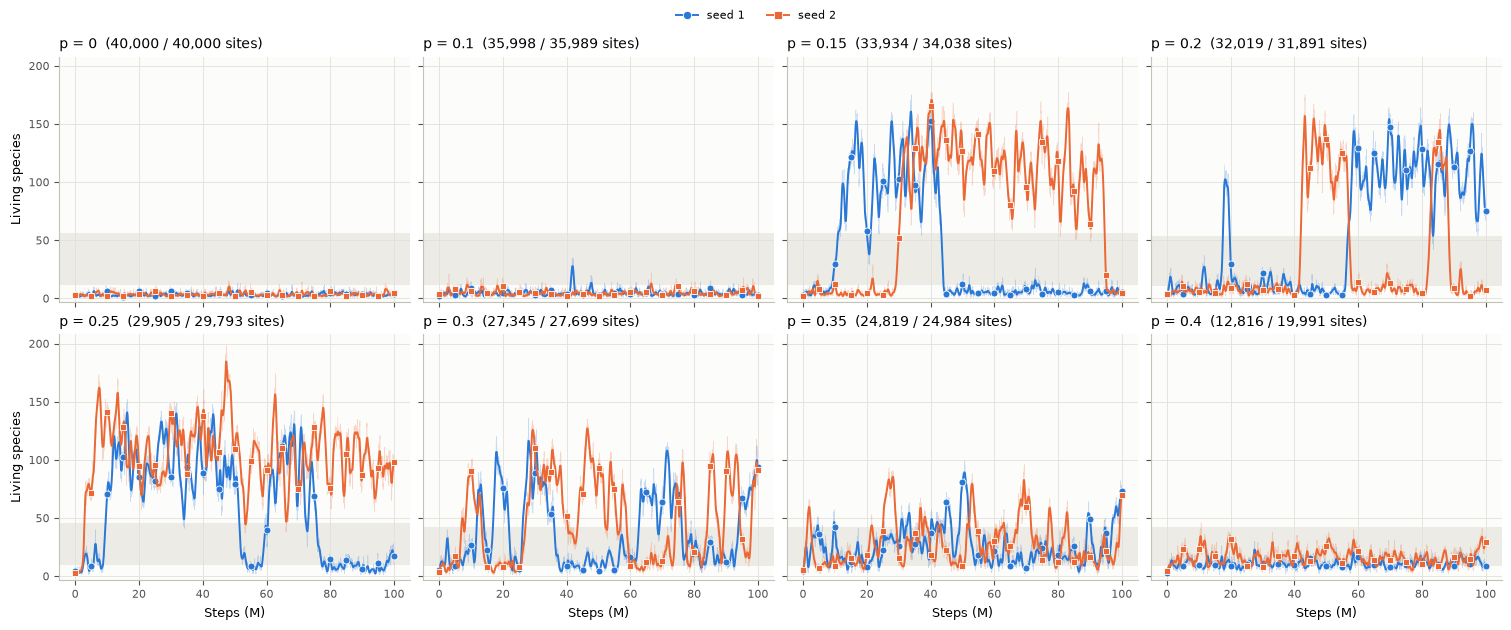

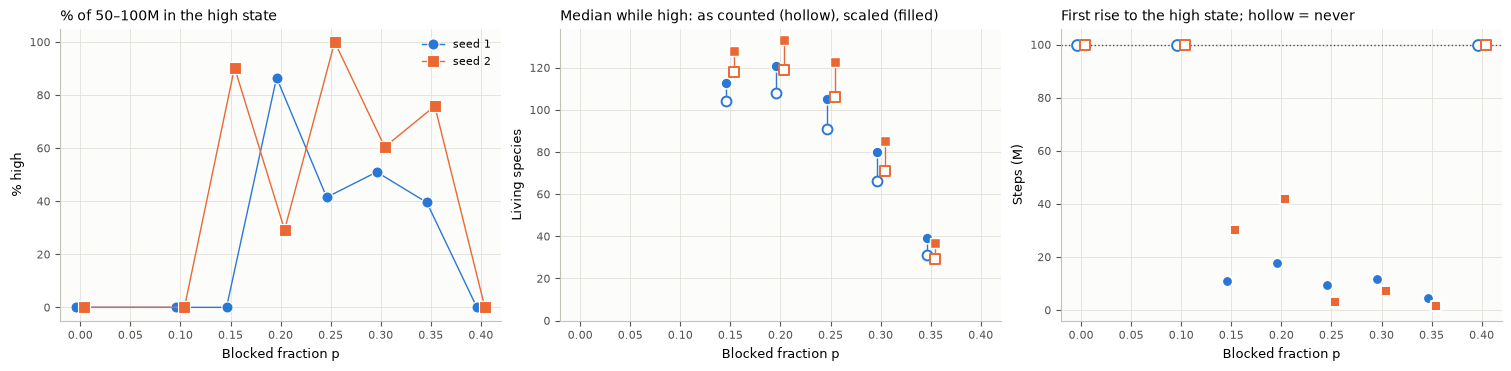

In [7]:
q3 = C.select(runs, group="q3_p_ladder_g003")
P_LADDER = (0, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4)
SEEDS = {"s1": ("seed 1", BLUE, "o"), "s2": ("seed 2", ORANGE, "s")}
OFFSET = {"s1": -0.004, "s2": 0.004}  # Keeps the two seeds' markers apart.
seed_of = lambda run: run["label"].split("_")[-1]

with plt.rc_context(C.RESULT_STYLE):
    fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharex=True, sharey=True, layout="constrained")
    for ax, p in zip(axes.flat, P_LADDER):
        panel = [run for run in q3 if run["p"] == p]
        C.state_band(ax, [(run, SEEDS[seed_of(run)][1]) for run in panel])
        for run in panel:
            label, color, marker = SEEDS[seed_of(run)]
            C.draw_trace(ax, run, color, marker, label)
        sites = " / ".join(f"{run['usable_sites']:,}" for run in sorted(panel, key=seed_of))
        ax.set_title(f"p = {p:g}  ({sites} sites)")
    axes[0, 0].set_ylim(-3, 1.05 * max(run["diversity"].max() for run in q3))
    for ax in axes[1]:
        ax.set_xlabel("Steps (M)")
    for ax in axes[:, 0]:
        ax.set_ylabel("Living species")
    fig.legend(handles=[C.handle(c, m, l) for l, c, m in SEEDS.values()], loc="outside upper center", ncols=2)
    plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), layout="constrained")
    for key, (label, color, marker) in SEEDS.items():
        line = sorted((run for run in q3 if seed_of(run) == key), key=lambda run: run["p"])
        xs = [run["p"] + OFFSET[key] for run in line]
        axes[0].plot(xs, [100 * run["share_high"] for run in line], color=color, marker=marker, ms=8,
                     lw=1, mec="white", mew=0.8, label=label)
        for x, run in zip(xs, line):
            if run["high"].any():  # Median while high, as counted (hollow) and scaled (filled).
                level = np.median(run["diversity"][run["high"]])
                scaled = level * np.sqrt(40_000 / run["usable_sites"])
                axes[1].plot([x, x], [level, scaled], color=color, lw=1, zorder=2)
                axes[1].scatter(x, level, marker=marker, s=50, facecolors="white", edgecolors=color,
                                linewidths=1.4, zorder=3)
                axes[1].scatter(x, scaled, marker=marker, s=60, color=color, edgecolors="white", zorder=3)
            rose = run["first_rise"] is not None
            axes[2].scatter(x, run["first_rise"] if rose else 100, marker=marker, s=60, zorder=3,
                            linewidths=1.4, color=color if rose else "white",
                            edgecolors="white" if rose else color)
    axes[0].set(ylabel="% high", title="% of 50–100M in the high state")
    axes[0].legend(loc="upper right")
    axes[1].set(ylabel="Living species", ylim=(0, None),
                title="Median while high: as counted (hollow), scaled (filled)")
    axes[2].axhline(100, color=GREY, ls=":", lw=1)
    axes[2].set(ylabel="Steps (M)", ylim=(-4, 106), title="First rise to the high state; hollow = never")
    for ax in axes:
        ax.set(xlabel="Blocked fraction p", xlim=(-0.02, 0.42))
    plt.show()

**Conclusion.** There is a window, p = 0.15–0.35, rather than a sharp optimum. Within it the high state
is largest at low p and reached soonest at high p.
- **Outside the window no seed reached the high state in 100M.** At p = 0 and 0.1 the runs stayed near
  3–5 species. At p = 0.4, close to the percolation threshold of the blocked fraction (about 0.41), the
  largest cluster had only 13,000–20,000 sites and 11–16 species on average.
- **Time spent high varies more between seeds than with p:** 87% and 29% at p = 0.2, 41% and 100% at
  0.25. At p = 0.15 seed 1 was high only from 11M to 44M.
- **The level of the high state falls with p:** a median of 104–119 species at p = 0.15–0.2, 91–106 at
  0.25, 66–71 at 0.3 and about 30 at 0.35. Scaled to a full lattice it still falls (113–133 down to
  37–39), so the smaller habitat does not explain the fall.
- **Rises come sooner at higher p:** the first rise came after 11–42M at p = 0.15–0.2 and after 1–12M at
  0.25–0.35.
- *Caveat:* at p = 0.35 the runs flicker between about 10 and 80 species without a separate high mode,
  so their % high rests on the lines borrowed from p = 0.3.